# Project: K-Means Clustering of Countries

### Soren Patel and Sam Pirkl

**Generative AI Usage:**
The vast majority of AI usage in this project was actually to quickly do research on the geographical, political, and cultural backgrounds of the countries in the dataset. When putting the cluster/country result into it and leaving the prompt open-ended, it revealed the geological trend. From there, I used it to research each cluster’s socioeconomic trends so I could compare with the results from the top 3 over/under representation analysis.

## 1. Load and Format the Data

The raw CSV (all_countries.csv) is in a long format: one row per
country, subcategory, and hours. We reshape it into a wider format: one row
per country and one column per subcategory; so each row represents that country's
full 24-hour day.

Subcategories appear in the same order for every country block
in the source file, so we can extract the subcategory list once from the first
country and reuse it as column names for all countries.

In [1]:
import pandas as pd
from sklearn.cluster import KMeans
import plotly.graph_objects as go

Read all the subcategories into a list and print for checking.

In [2]:
df = pd.read_csv("all_countries.csv")

target = df["countryISO3"].iloc[0]

subcats = []
for country, subcat in zip(df["countryISO3"], df["Subcategory"]):
    if country != target:
        break
    else:
        subcats.append(subcat)
print(subcats)

['Food preparation', 'Food growth & collection', 'Food processing', 'Materials', 'Energy', 'Infrastructure', 'Buildings', 'Artifacts', 'Inhabited environment', 'Sleep & bedrest', 'Waste management', 'Physical child care', 'Health care', 'Hygiene & grooming', 'Schooling & research', 'Religious practice', 'Human transportation', 'Material transportation', 'Allocation', 'Social', 'Active recreation', 'Meals', 'Passive', 'Interactive']


Create a country:hours map, where key = the country code and value = an array of the hours they spent on various subcategories.
Convert to a dataframe and print the first 5 rows as an example.

In [3]:
country_hours_map = {}
hour_list = []

for row_index, (country, hours) in enumerate(zip(df["countryISO3"], df["hoursPerDayCombined"])):
    if country == target:
        hour_list.append(hours)
    if  row_index == len(df)-1 or df["countryISO3"].iloc[row_index+1] != target:
        country_hours_map[country] = hour_list
        hour_list = []
        target = df["countryISO3"].iloc[row_index]
        hour_list.append(hours)

In [4]:
df = pd.DataFrame.from_dict(country_hours_map, orient="index", columns=subcats)
df.index.name = "Country"
df.head()

,Food preparation,Food growth & collection,Food processing,Materials,Energy,Infrastructure,Buildings,Artifacts,Inhabited environment,Sleep & bedrest,...,Schooling & research,Religious practice,Human transportation,Material transportation,Allocation,Social,Active recreation,Meals,Passive,Interactive
Country,,,,,,,,,,,,,,,,,,,,,
ABW,1.47,0.17,0.00,0.03,0.05,0.07,0.22,0.25,1.41,8.21,...,1.22,0.23,0.73,0.12,1.54,1.00,0.46,1.27,2.12,1.28
AFG,1.14,0.88,0.10,0.04,0.02,0.07,0.20,0.18,0.68,9.49,...,1.33,0.29,0.75,0.25,0.74,1.80,0.23,1.62,2.05,0.62
AGO,0.81,1.06,0.02,0.10,0.08,0.02,0.03,0.42,0.72,9.79,...,1.95,0.44,1.02,0.48,0.49,1.05,0.44,1.14,1.84,0.96
ALB,1.10,0.82,0.04,0.05,0.04,0.03,0.28,0.40,0.83,9.40,...,1.03,0.07,1.11,0.12,0.60,0.73,0.43,2.02,3.06,0.61
ARE,0.88,0.36,0.04,0.04,0.03,0.04,0.21,0.31,0.86,9.45,...,0.93,0.47,0.77,0.21,0.79,1.09,0.49,1.79,3.09,0.90


## 2. Choosing the Number of Clusters (k)

Before running K-Means, we ran k from 2 to 50 and plotted inertia
(intra-cluster sum of squared euclidean distances) against k to find an "elbow," or
the point of diminishing returns from adding more clusters. This identified
**k = 7** as a good balance.

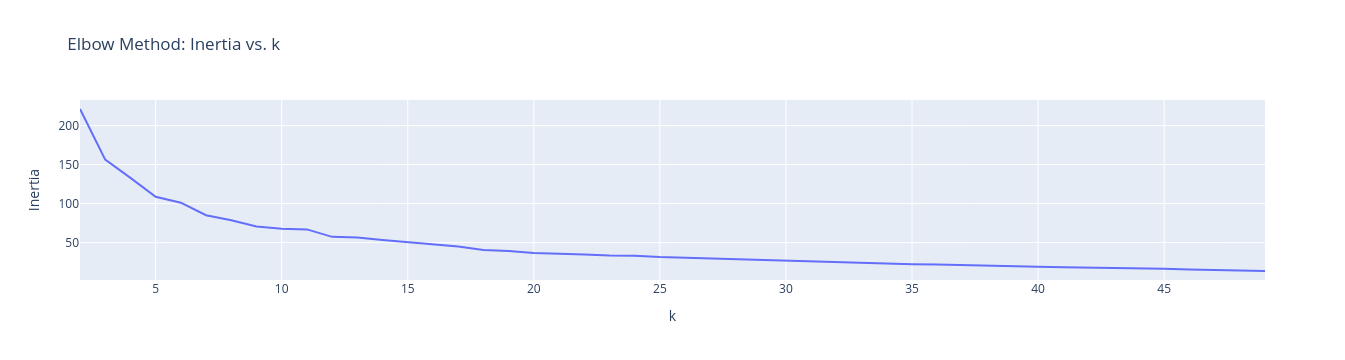

In [5]:
subcat_frame = df[subcats]
inertias = []
ks = range(2, 50)
for k_val in ks:
    km_temp = KMeans(n_clusters=k_val, n_init='auto', random_state=2028)
    km_temp.fit(subcat_frame)
    inertias.append(km_temp.inertia_)

fig = go.Figure()
fig.add_trace(go.Scatter(x=list(ks), y=inertias))
fig.update_layout(title="Elbow Method: Inertia vs. k", xaxis_title="k", yaxis_title="Inertia")
fig.show()

## 3. Run K-Means with k = 7

We ran K-Means directly on the raw hours-per-day matrix, using
100 random initializations and a fixed random seed to reproduce the same output. (Class year 2028 for reasoning).

Create 7 clusters and print all cluster sizes.

In [6]:
k = 7
km = KMeans(n_clusters=k, n_init=100, random_state=2028)
km.fit(subcat_frame)

cluster_sizes = [int(sum(km.labels_ == cluster)) for cluster in range(k)]
print(cluster_sizes)

[57, 21, 26, 24, 24, 29, 18]


## 4. Attach Cluster Labels and Inspect Membership

We attach each country's assigned cluster back onto the dataframe, then list
which countries fall into each cluster to begin examining what each group could possibly
represent, or find an explanation for the clustering result.

Print the code of each country in each cluster.

In [7]:
df["cluster"] = km.labels_

for cluster in range(k):
    countries_in_cluster = df.index[df["cluster"] == cluster].tolist()
    print(f"Cluster {cluster} ({len(countries_in_cluster)} countries): {countries_in_cluster}\n")

Cluster 0 (57 countries): ['ARG', 'AUS', 'AUT', 'BEL', 'BGR', 'BIH', 'BLR', 'BOL', 'BRA', 'CAN', 'CHE', 'CHL', 'CZE', 'DEU', 'DNK', 'ECU', 'ESP', 'EST', 'FIN', 'FRA', 'GBR', 'GRC', 'GUF', 'GUY', 'HKG', 'HRV', 'HUN', 'IRL', 'IRN', 'ISL', 'ITA', 'KOR', 'LTU', 'LUX', 'LVA', 'MKD', 'MLT', 'MNE', 'MUS', 'NLD', 'NOR', 'NZL', 'PER', 'POL', 'PRT', 'PRY', 'ROU', 'SRB', 'SUR', 'SVK', 'SVN', 'SWE', 'TUN', 'UKR', 'URY', 'USA', 'VEN']

Cluster 1 (21 countries): ['BFA', 'CIV', 'COL', 'CPV', 'GHA', 'GIN', 'GMB', 'GNB', 'KAZ', 'KGZ', 'LBR', 'MLI', 'MRT', 'NER', 'NGA', 'SEN', 'SLE', 'TGO', 'TJK', 'TKM', 'UZB']

Cluster 2 (26 countries): ['ABW', 'ATG', 'BHS', 'BLZ', 'BRB', 'CRI', 'CUB', 'CUW', 'DOM', 'GLP', 'GRD', 'GTM', 'HND', 'HTI', 'JAM', 'LCA', 'MEX', 'MTQ', 'NIC', 'PAN', 'PRI', 'RUS', 'SLV', 'TTO', 'VCT', 'VIR']

Cluster 3 (24 countries): ['BDI', 'CHN', 'COM', 'DJI', 'ERI', 'ETH', 'KEN', 'MAC', 'MDA', 'MDG', 'MNG', 'MOZ', 'MWI', 'MYT', 'PRK', 'REU', 'RWA', 'SOM', 'SSD', 'SYC', 'TZA', 'UGA', 'ZMB', 

## 5. Cluster Analysis: What Does Each Group's Average Day Look Like?

For each cluster, we compute the mean hours per subcategory, then subtract
the global average across all countries. This highlights what is
distinctive about each cluster.

Print the mean hours per day of each subcategory for each cluster.

In [8]:
cluster_profiles = df.groupby("cluster")[subcats].mean()
global_avg = df[subcats].mean()
cluster_deviation = cluster_profiles - global_avg

print("Cluster profiles (mean hours/day per subcategory):")
cluster_profiles.round(2)

Cluster profiles (mean hours/day per subcategory):


,Food preparation,Food growth & collection,Food processing,Materials,Energy,Infrastructure,Buildings,Artifacts,Inhabited environment,Sleep & bedrest,...,Schooling & research,Religious practice,Human transportation,Material transportation,Allocation,Social,Active recreation,Meals,Passive,Interactive
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.88,0.27,0.06,0.04,0.04,0.06,0.25,0.43,0.95,8.85,...,0.89,0.14,0.97,0.37,1.18,0.90,0.61,1.63,3.00,1.00
1,0.63,0.81,0.07,0.11,0.03,0.03,0.15,0.27,0.77,8.77,...,1.36,0.30,0.95,0.25,0.92,1.45,0.44,1.57,2.32,1.28
2,1.14,0.57,0.07,0.08,0.05,0.07,0.25,0.40,1.28,8.25,...,1.21,0.21,0.70,0.17,1.32,1.03,0.45,1.27,2.09,1.29
3,0.78,1.21,0.11,0.11,0.03,0.03,0.17,0.25,0.82,8.95,...,1.03,0.15,0.98,0.31,0.83,0.88,0.42,1.82,2.32,1.08
4,0.59,0.85,0.08,0.07,0.03,0.04,0.38,0.45,0.58,8.51,...,1.04,0.05,1.08,0.36,1.10,0.66,0.28,1.81,3.48,0.62
5,0.92,0.34,0.04,0.05,0.05,0.05,0.22,0.25,0.85,9.51,...,0.96,0.47,0.81,0.19,0.79,1.17,0.49,1.65,3.05,0.88
6,0.97,0.88,0.07,0.07,0.06,0.02,0.11,0.36,0.71,9.65,...,1.64,0.38,0.91,0.39,0.58,1.40,0.33,1.35,1.97,0.79


Print each cluster's deviation from the global average.

In [9]:
print("Cluster deviation from global average:")
cluster_deviation.round(2)

Cluster deviation from global average:


,Food preparation,Food growth & collection,Food processing,Materials,Energy,Infrastructure,Buildings,Artifacts,Inhabited environment,Sleep & bedrest,...,Schooling & research,Religious practice,Human transportation,Material transportation,Allocation,Social,Active recreation,Meals,Passive,Interactive
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.03,-0.34,-0.01,-0.03,-0.00,0.02,0.02,0.08,0.07,-0.05,...,-0.20,-0.08,0.05,0.07,0.17,-0.13,0.14,0.03,0.30,0.00
1,-0.23,0.20,0.00,0.04,-0.01,-0.02,-0.08,-0.09,-0.11,-0.13,...,0.27,0.07,0.03,-0.04,-0.09,0.43,-0.02,-0.03,-0.38,0.29
2,0.28,-0.04,0.00,0.01,0.01,0.02,0.02,0.04,0.40,-0.65,...,0.12,-0.01,-0.22,-0.13,0.32,-0.00,-0.01,-0.33,-0.61,0.29
3,-0.07,0.59,0.04,0.03,-0.01,-0.02,-0.06,-0.11,-0.06,0.05,...,-0.07,-0.08,0.06,0.01,-0.18,-0.15,-0.04,0.22,-0.37,0.08
4,-0.26,0.24,0.01,0.00,-0.01,-0.01,0.15,0.09,-0.29,-0.40,...,-0.06,-0.18,0.16,0.07,0.10,-0.37,-0.19,0.21,0.78,-0.38
5,0.06,-0.28,-0.03,-0.02,0.00,0.00,-0.01,-0.10,-0.03,0.61,...,-0.13,0.24,-0.11,-0.11,-0.22,0.14,0.03,0.05,0.35,-0.11
6,0.12,0.27,0.00,0.00,0.02,-0.02,-0.12,-0.00,-0.17,0.74,...,0.54,0.15,-0.01,0.09,-0.43,0.38,-0.13,-0.25,-0.72,-0.20


Comparing the above two results, we can now see which subcategories each cluster spends the most/least time difference from the global average on.

In [10]:
for cluster in range(k):
    row = cluster_deviation.loc[cluster].sort_values(ascending=False)
    print(f"\nCluster {cluster} — spends MORE time than average on: {row.head(3).index.tolist()}")
    print(f"Cluster {cluster} — spends LESS time than average on: {row.tail(3).index.tolist()}")


Cluster 0 — spends MORE time than average on: ['Passive', 'Allocation', 'Active recreation']
Cluster 0 — spends LESS time than average on: ['Social', 'Schooling & research', 'Food growth & collection']

Cluster 1 — spends MORE time than average on: ['Social', 'Interactive', 'Schooling & research']
Cluster 1 — spends LESS time than average on: ['Sleep & bedrest', 'Food preparation', 'Passive']

Cluster 2 — spends MORE time than average on: ['Inhabited environment', 'Physical child care', 'Allocation']
Cluster 2 — spends LESS time than average on: ['Meals', 'Passive', 'Sleep & bedrest']

Cluster 3 — spends MORE time than average on: ['Food growth & collection', 'Meals', 'Interactive']
Cluster 3 — spends LESS time than average on: ['Social', 'Allocation', 'Passive']

Cluster 4 — spends MORE time than average on: ['Passive', 'Hygiene & grooming', 'Food growth & collection']
Cluster 4 — spends LESS time than average on: ['Social', 'Interactive', 'Sleep & bedrest']

Cluster 5 — spends MORE 

## 5. Further Analysis

**Geography:**
	Using AI to quickly analyze the countries in each cluster without feeding it the dataset, it noticed an immediate trend and produced these results (the next 7 lines) by geographical location. This may in part explain some of the other trends in how the countries in each cluster spend their time; however no assumption can be made from just this.

Cluster 0 (57): Europe, South America, US/Canada/Australia/NZ, South Korea — high/middle-income, urbanized  
Cluster 1 (21): West Africa + Central Asia — lower-income, agrarian  
Cluster 2 (26): Caribbean + Central America, plus Russia (outlier)  
Cluster 3 (24): East Africa + China, Mongolia, North Korea — poor/agrarian; China is a notable outlier given its economic size  
Cluster 4 (24): Southeast Asia + Pacific islands, plus Japan/Taiwan/Singapore  
Cluster 5 (29): Middle East/North Africa + Southern Africa + Caucasus  
Cluster 6 (18): South Asia + Central Africa — high population density, lower-income  


Analysis:
	Combining the geographical patterns with the activities that each cluster spent the most/least time on in comparison to the global average, these results can potentially be explained.  
Cluster 0  
High passive and active recreation, low food growth and collection  
Consistent with post-agrarian high income economy  
Low social may be counterintuitive, but follows research on societies prioritizing solo screen-based recreation  
Cluster 1  
High social/interactive and low sleep/food prep  
Communal, labor intensive societies  
Work demands for subsistence and daily life structured around interpersonal activity/marketplace  
Cluster 2  
High inhabited environment and childcare, low meals/sleep  
Not much correlation here, Russia may be an outlier skewing data  
Cluster 3  
High food growth and collection, low social/allocation  
subsistence/agricultural societies  
Explains China’s placement here, as huge rural population does agricultural labor  
Cluster 4  
High hygiene/grooming and food growth, low social/sleep  
Another puzzling cluster like cluster 2, many different economies represented here (eg. Vanuatu vs. Singapore)  
May be due to tropical climate regions, but also a weaker fit  
Cluster 5  
High sleep and religious practice  
Aligns highly with large amount of Muslim practice in Middle East and N. Africa  
One of the only clusters to show a cultural practice as opposed to an economic practice as its main pattern  
Cluster 6  
High schooling, research, low meals and allocation  
Young populations explain more average schooling time  


**Population Analysis:**  
Using the dataset from https://datahub.io/core/population, we were able to calculate the population mean/median for each cluster. Luckily, the CSV from this site already had countries in terms of their 3-letter country code. Note: we used 2024 as the most recent year as 2025/2026 datasets were incomplete and resulted in NaN values.

In [11]:
pop_df = pd.read_csv("population.csv")
pop_df = pop_df[pop_df["Year"] == 2024]
pop_df = pop_df.set_index("Country Code")["Value"]

df["population"] = df.index.map(pop_df)

avg_pop_by_cluster = df.groupby("cluster")["population"].mean()
median_pop_by_cluster = df.groupby("cluster")["population"].median()

print("Average population per cluster:")
print(avg_pop_by_cluster.round(0))

print("\nMedian population per cluster:")
print(median_pop_by_cluster.round(0))

Average population per cluster:
cluster
0     27730614.0
1     27472926.0
2     15419914.0
3     88195747.0
4     36230158.0
5     21177704.0
6    122148864.0
Name: population, dtype: float64

Median population per cluster:
cluster
0     9370024.0
1    14754785.0
2     3021235.0
3    17821762.0
4     1400638.0
5     6593492.0
6    21107562.0
Name: population, dtype: float64


Observations from population analysis - no notable relationship between cluster and population.  
Massive mean populations in clusters 3 and 6 primarily due to
China in cluster 3,
India in cluster 6  
Cluster 2 has the smallest mean population. This makes sense due to it being mostly small/Caribbean countries.  
No clear relationship between population data and the activities which clusters spent time on.
